# ADO2 — Leis de Newton e Aplicações
Simulação interativa de três sistemas: **plano inclinado com atrito e tração**, **força centrípeta** e **força de arrasto**.

**Como usar:** menu *Ambiente de execução → Executar tudo* (Ctrl+F9). A interface aparece na última célula.

> Se os sliders não responderem, use *Ambiente de execução → Reiniciar e executar tudo*. Para rodar no computador: `python simulacao_newton.py`.

## Configuração

In [8]:
# Instala as dependências necessárias
!pip install -q ipympl matplotlib-inline

# Ativa o gestor de widgets customizados do Google Colab
from google.colab import output
output.enable_custom_widget_manager()

%matplotlib widget

In [9]:
"""
ADO2 — Leis de Newton e Aplicações
Mecânica e Física Moderna — Ciência da Computação

Simulação interativa (matplotlib.widgets) de três sistemas mecânicos:
  1) Plano inclinado com atrito e tração (bloco m1 no plano + bloco m2 pendurado)
  2) Força centrípeta (MCU) — com modo extra "carro na curva" (extensão opcional)
  3) Força de arrasto (queda com arrasto linear ou quadrático)

Nenhum método de integração numérica é usado: todas as grandezas vêm de
FÓRMULAS FECHADAS avaliadas diretamente sobre um vetor de tempo
t = np.linspace(...), com álgebra vetorizada do NumPy.

Como rodar:
    pip install numpy matplotlib
    python simulacao_newton.py
"""

import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.widgets import Button, RadioButtons, Slider

# ----------------------------------------------------------------------------
# Constantes e estilo
# ----------------------------------------------------------------------------
G = 9.81  # aceleração da gravidade (m/s²)

TEAL = '#0D9488'
AMBER = '#F59E0B'
PURPLE = '#8B5CF6'
BLUE = '#3B82F6'
RED = '#EF4444'
GRAY = '#94A3B8'
DARK = '#1E293B'
PAINEL = '#F1F5F9'

plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'font.family': 'DejaVu Sans',
})

## Sistema 1 — Plano inclinado com atrito e tração
$N = m_1 g\cos\theta$, $\quad F_{motriz} = m_2 g - m_1 g\sin\theta$

Se $|F_{motriz}| \le \mu_s N$: $a = 0$ (equilíbrio estático). Senão: $a = \dfrac{F_{motriz} - \mu_k N\,\mathrm{sinal}(F_{motriz})}{m_1 + m_2}$

MRUV: $x(t) = \tfrac12 a t^2$, $v(t) = a t$; tração $T = m_2(g - a)$.

In [10]:
# ============================================================================
# SISTEMA 1 — PLANO INCLINADO COM ATRITO E TRAÇÃO
# ============================================================================
# Convenção de sinal: sentido POSITIVO = m2 desce e m1 sobe o plano.
def calcular_aceleracao_sistema(massa_bloco_plano, massa_bloco_suspenso, angulo_graus,
                                coeficiente_estatico, coeficiente_cinetico,
                                aceleracao_gravidade=G):
    """Devolve (a, N, F_motriz, estado) a partir da 2ª Lei de Newton (ΣF = m·a)."""
    m1, m2, g = massa_bloco_plano, massa_bloco_suspenso, aceleracao_gravidade

    # Converte graus para radianos (np.sin/np.cos trabalham em radianos)
    angulo_radianos = np.radians(angulo_graus)

    # 2ª Lei de Newton para m1 na direção PERPENDICULAR ao plano: o bloco não
    # acelera nessa direção, então N − m1·g·cos(θ) = 0  →  N = m1·g·cos(θ)
    forca_normal = m1 * g * np.cos(angulo_radianos)

    # Força motriz: o que "puxa" o sistema antes do atrito.
    # Peso de m2 (puxa no sentido +) menos a componente do peso de m1 ao longo
    # do plano (m1·g·sen θ, puxa no sentido −):  F_motriz = m2·g − m1·g·sen(θ)
    forca_motriz = m2 * g - m1 * g * np.sin(angulo_radianos)

    # Atrito estático máximo (lei de Coulomb do atrito): f_s,max = μs·N
    limite_atrito_estatico = coeficiente_estatico * forca_normal

    # Se o atrito estático consegue equilibrar a força motriz, nada se move:
    # |F_motriz| ≤ μs·N  →  a = 0  (EQUILÍBRIO ESTÁTICO)
    if np.abs(forca_motriz) <= limite_atrito_estatico:
        aceleracao = 0.0
        estado_movimento = "Equilíbrio estático"
    else:
        # Em movimento, age o atrito CINÉTICO f_k = μk·N, sempre CONTRA o
        # movimento — e o movimento tem o sentido de F_motriz, por isso o
        # termo sinal(F_motriz).
        # 2ª Lei em m1 (ao longo do plano): T − m1·g·sen θ − f_k·sinal = m1·a
        # 2ª Lei em m2 (vertical):          m2·g − T             = m2·a
        # Somando as duas, a tração T se cancela:
        #   (m1 + m2)·a = F_motriz − μk·N·sinal(F_motriz)
        sinal_forca = np.sign(forca_motriz)
        forca_atrito_cinetico = coeficiente_cinetico * forca_normal
        aceleracao = (forca_motriz - forca_atrito_cinetico * sinal_forca) / (m1 + m2)
        estado_movimento = "Em movimento"

    return aceleracao, forca_normal, forca_motriz, estado_movimento


def simular_plano_inclinado(massa_bloco_plano, massa_bloco_suspenso, angulo_graus,
                            coeficiente_estatico, coeficiente_cinetico,
                            tempo_maximo=5.0, numero_pontos=300, aceleracao_gravidade=G):
    aceleracao, forca_normal, forca_motriz, estado_movimento = calcular_aceleracao_sistema(
        massa_bloco_plano, massa_bloco_suspenso, angulo_graus,
        coeficiente_estatico, coeficiente_cinetico, aceleracao_gravidade
    )

    # Vetor de instantes de tempo onde as fórmulas serão avaliadas
    vetor_tempo = np.linspace(0, tempo_maximo, numero_pontos)
    posicao_inicial = 0.0
    velocidade_inicial = 0.0

    # Como a aceleração é CONSTANTE, valem as equações do MRUV:
    #   x(t) = x0 + v0·t + ½·a·t²      v(t) = v0 + a·t
    posicao = posicao_inicial + velocidade_inicial * vetor_tempo + 0.5 * aceleracao * vetor_tempo ** 2
    velocidade = velocidade_inicial + aceleracao * vetor_tempo

    # Tração no fio — 2ª Lei aplicada só em m2 (positivo para baixo):
    #   m2·g − T = m2·a  →  T = m2·(g − a)
    tracao_no_fio = massa_bloco_suspenso * (aceleracao_gravidade - aceleracao)

    return {
        "tempo": vetor_tempo,
        "posicao": posicao,
        "velocidade": velocidade,
        "tracao": tracao_no_fio,
        "aceleracao": aceleracao,
        "estado": estado_movimento,
        "normal": forca_normal,
        "forca_motriz": forca_motriz,
    }

## Sistema 2 — Força centrípeta (MCU)
$\omega = v/R$, $\quad x(t) = R\cos(\omega t)$, $\quad y(t) = R\sin(\omega t)$, $\quad F_c = \dfrac{m v^2}{R} = m\omega^2 R$

Extensão: carro na curva plana, $v_{max} = \sqrt{\mu g R}$.

In [11]:
# ============================================================================
# SISTEMA 2 — FORÇA CENTRÍPETA (MOVIMENTO CIRCULAR UNIFORME)
# ============================================================================
def simular_movimento_circular_uniforme(massa_corpo, raio_circunferencia, velocidade_tangencial,
                                        tempo_maximo=5.0, numero_pontos=300):
    vetor_tempo = np.linspace(0, tempo_maximo, numero_pontos)

    # Velocidade angular do MCU: ω = v / R  (protege contra raio zero)
    velocidade_angular = velocidade_tangencial / raio_circunferencia if raio_circunferencia > 0 else 0.0

    # Posição no MCU: o ângulo cresce linearmente, φ(t) = ω·t, e a projeção
    # nos eixos dá  x(t) = R·cos(ωt),  y(t) = R·sen(ωt)
    fase_angular = velocidade_angular * vetor_tempo
    posicao_x = raio_circunferencia * np.cos(fase_angular)
    posicao_y = raio_circunferencia * np.sin(fase_angular)

    # 2ª Lei de Newton na direção radial: a força resultante aponta para o
    # centro e vale m·a_c, com a_c = v²/R = ω²·R  →  Fc = m·v²/R = m·ω²·R
    forca_centripeta = massa_corpo * velocidade_angular ** 2 * raio_circunferencia

    # Período de uma volta: T = 2π / ω
    periodo = 2 * np.pi / velocidade_angular if velocidade_angular > 0 else np.inf

    return {
        "tempo": vetor_tempo,
        "posicao_x": posicao_x,
        "posicao_y": posicao_y,
        "velocidade_angular": velocidade_angular,
        "forca_centripeta": forca_centripeta,
        "periodo": periodo,
    }


def velocidade_maxima_curva(coeficiente_atrito, raio, aceleracao_gravidade=G):
    """Extensão opcional: carro em curva plana.

    Quem fornece a força centrípeta é o atrito ESTÁTICO pneu-pista, que tem
    valor máximo μ·N = μ·m·g (pista plana: N = m·g). O carro não derrapa
    enquanto  m·v²/R ≤ μ·m·g  →  v ≤ v_max = √(μ·g·R)  (a massa se cancela).
    """
    return np.sqrt(coeficiente_atrito * aceleracao_gravidade * raio)

## Sistema 3 — Força de arrasto
**Linear** ($F = -bv$): $v_T = mg/b$, $\tau = m/b$, $v(t) = v_T(1 - e^{-t/\tau})$, $y(t) = v_T t - v_T\tau(1 - e^{-t/\tau})$

**Quadrático** ($F = -cv|v|$): $v_T = \sqrt{mg/c}$, $v(t) = v_T\tanh(gt/v_T)$, $y(t) = \dfrac{v_T^2}{g}\ln\cosh(gt/v_T)$

In [12]:
# ============================================================================
# SISTEMA 3 — FORÇA DE ARRASTO (QUEDA VERTICAL)
# ============================================================================
# y e v são medidos PARA BAIXO, partindo do repouso (y0 = 0, v0 = 0).
def tempo_95_porcento(massa, coeficiente, modelo, aceleracao_gravidade=G):
    """Tempo para atingir 95% da velocidade terminal (fórmula fechada)."""
    g = aceleracao_gravidade
    if modelo == "linear":
        # 1 − e^(−t/τ) = 0,95  →  t = τ·ln(20)
        return (massa / coeficiente) * np.log(20)
    # tanh(g·t/v_T) = 0,95  →  t = (v_T/g)·artanh(0,95)
    v_terminal = np.sqrt(massa * g / coeficiente)
    return (v_terminal / g) * np.arctanh(0.95)


def simular_arrasto(massa, coeficiente, modelo="linear", tempo_maximo=20.0,
                    numero_pontos=400, aceleracao_gravidade=G):
    g = aceleracao_gravidade
    t = np.linspace(0, tempo_maximo, numero_pontos)

    if modelo == "linear":
        # F_arrasto = −b·v.  2ª Lei:  m·dv/dt = m·g − b·v
        # Velocidade terminal: quando a aceleração zera, m·g = b·v_T → v_T = m·g/b
        # Constante de tempo: τ = m/b
        # Solução fechada (já resolvida):  v(t) = v_T·(1 − e^(−t/τ))
        b = coeficiente
        v_terminal = massa * g / b
        tau = massa / b
        velocidade = v_terminal * (1 - np.exp(-t / tau))
        # Posição = integral de v(t):  y(t) = v_T·t − v_T·τ·(1 − e^(−t/τ))
        posicao = v_terminal * t - v_terminal * tau * (1 - np.exp(-t / tau))
    else:
        # F_arrasto = −c·v·|v|.  2ª Lei:  m·dv/dt = m·g − c·v²
        # Velocidade terminal: m·g = c·v_T²  →  v_T = √(m·g/c)
        # Solução fechada:  v(t) = v_T·tanh(g·t / v_T)
        c = coeficiente
        v_terminal = np.sqrt(massa * g / c)
        tau = None
        u = g * t / v_terminal
        velocidade = v_terminal * np.tanh(u)
        # Posição: y(t) = (v_T²/g)·ln(cosh(g·t/v_T)).
        # ln(cosh u) é calculado como logaddexp(u, −u) − ln 2, que é a MESMA
        # expressão matemática, mas não estoura (overflow) para u grande.
        posicao = (v_terminal ** 2 / g) * (np.logaddexp(u, -u) - np.log(2))

    # Queda livre (sem arrasto), para comparação: v = g·t,  y = ½·g·t²
    velocidade_livre = g * t
    posicao_livre = 0.5 * g * t ** 2

    return {
        "tempo": t,
        "velocidade": velocidade,
        "posicao": posicao,
        "velocidade_livre": velocidade_livre,
        "posicao_livre": posicao_livre,
        "v_terminal": v_terminal,
        "tau": tau,
        "t95": tempo_95_porcento(massa, coeficiente, modelo, g),
    }

## Interface gráfica

In [13]:
# ============================================================================
# INTERFACE GRÁFICA
# ============================================================================
SISTEMAS = ["1) Plano inclinado", "2) Força centrípeta", "3) Força de arrasto"]
MODOS = {
    1: ("μs = μk", "μs independente"),
    2: ("Fio (massa girando)", "Carro na curva"),
    3: ("Linear  F = −b·v", "Quadrático  F = −c·v|v|"),
}
CHAVES_MODO = {1: ("igual", "separado"), 2: ("fio", "carro"), 3: ("linear", "quadratico")}
TITULOS_MODO = {1: "Atrito estático", 2: "Modo", 3: "Modelo de arrasto"}

# Posições (em fração da figura) das "vagas" de sliders, de cima para baixo
Y_SLOTS = [0.300, 0.245, 0.190, 0.135, 0.080]


def criar_interface():
    fig = plt.figure(figsize=(14, 8))
    try:
        fig.canvas.manager.set_window_title("ADO2 — Leis de Newton")
    except Exception:
        pass
    fig.suptitle("Leis de Newton — Simulação Interativa", fontsize=15,
                 fontweight="bold", color=DARK, x=0.6, y=0.975)

    # Dois gráficos principais lado a lado
    ax_a = fig.add_axes([0.28, 0.44, 0.30, 0.46])
    ax_b = fig.add_axes([0.67, 0.44, 0.30, 0.46])

    # ---- Menu de sistemas -------------------------------------------------
    ax_sis = fig.add_axes([0.015, 0.73, 0.20, 0.17], facecolor=PAINEL)
    ax_sis.set_title("Sistema", fontsize=11, loc="left", fontweight="bold")
    radio_sis = RadioButtons(ax_sis, SISTEMAS, active=0)

    # ---- Menus de modo (um por sistema, sobrepostos; só um fica visível) --
    radios_modo = {}
    for s in (1, 2, 3):
        ax_m = fig.add_axes([0.015, 0.555, 0.20, 0.12], facecolor=PAINEL)
        ax_m.set_title(TITULOS_MODO[s], fontsize=11, loc="left", fontweight="bold")
        radios_modo[s] = RadioButtons(ax_m, MODOS[s], active=0)

    # ---- Painel de resultados numéricos ------------------------------------
    ax_info = fig.add_axes([0.015, 0.03, 0.20, 0.47])
    ax_info.axis("off")
    txt_info = ax_info.text(
        0.0, 1.0, "", va="top", ha="left", family="DejaVu Sans Mono", fontsize=9.5,
        color=DARK, transform=ax_info.transAxes,
        bbox=dict(boxstyle="round,pad=0.6", facecolor=PAINEL, edgecolor=GRAY),
    )

    # ---- Sliders ------------------------------------------------------------
    def novo_slider(vaga, rotulo, vmin, vmax, vini, passo, cor):
        ax = fig.add_axes([0.37, Y_SLOTS[vaga], 0.39, 0.03])
        return Slider(ax, rotulo, vmin, vmax, valinit=vini, valstep=passo, color=cor)

    sl = {
        # Sistema 1
        "m1": novo_slider(0, "m₁ bloco no plano (kg)", 0.1, 20, 5.0, 0.1, TEAL),
        "m2": novo_slider(1, "m₂ bloco pendurado (kg)", 0.1, 20, 4.0, 0.1, TEAL),
        "theta": novo_slider(2, "θ ângulo do plano (°)", 0, 80, 25.0, 0.5, TEAL),
        "mu_k": novo_slider(3, "μk atrito cinético", 0, 1, 0.20, 0.005, TEAL),
        "mu_s": novo_slider(4, "μs atrito estático", 0, 1, 0.30, 0.005, TEAL),
        # Sistema 2 — modo fio
        "m_c": novo_slider(0, "m massa (kg)", 0.1, 10, 2.0, 0.1, BLUE),
        "R_c": novo_slider(1, "R raio do fio (m)", 0.1, 5, 1.5, 0.05, BLUE),
        "v_c": novo_slider(2, "v velocidade (m/s)", 0.1, 20, 3.0, 0.1, BLUE),
        # Sistema 2 — modo carro
        "m_car": novo_slider(0, "m carro (kg)", 500, 3000, 1200, 10, BLUE),
        "R_car": novo_slider(1, "R raio da curva (m)", 5, 200, 50, 1, BLUE),
        "v_car": novo_slider(2, "v velocidade (m/s)", 1, 50, 15, 0.5, BLUE),
        "mu_car": novo_slider(3, "μ pneu–pista", 0.05, 1.2, 0.70, 0.01, BLUE),
        # Sistema 3
        "m_d": novo_slider(0, "m massa (kg)", 0.1, 100, 5.0, 0.1, PURPLE),
        "k_d": novo_slider(1, "b coef. de arrasto (kg/s)", 0.05, 5, 1.0, 0.01, PURPLE),
        "t_d": novo_slider(2, "t máx do gráfico (s)", 1, 60, 20, 0.5, PURPLE),
    }
    grupos = {
        (1, "igual"): ["m1", "m2", "theta", "mu_k"],
        (1, "separado"): ["m1", "m2", "theta", "mu_k", "mu_s"],
        (2, "fio"): ["m_c", "R_c", "v_c"],
        (2, "carro"): ["m_car", "R_car", "v_car", "mu_car"],
        (3, "linear"): ["m_d", "k_d", "t_d"],
        (3, "quadratico"): ["m_d", "k_d", "t_d"],
    }

    ax_reset = fig.add_axes([0.86, 0.08, 0.11, 0.05])
    btn_reset = Button(ax_reset, "Restaurar", color=PAINEL, hovercolor="#E2E8F0")

    # Borda completa nos painéis de controle (o rcParams acima remove topo/direita)
    for ax_ctrl in [ax_sis, ax_reset] + [r.ax for r in radios_modo.values()]:
        for borda in ax_ctrl.spines.values():
            borda.set_visible(True)
            borda.set_color(GRAY)

    estado = {"sistema": 1, "modo": {1: "igual", 2: "fio", 3: "linear"},
              "t0": time.perf_counter(), "anim": None}

    # ------------------------------------------------------------------------
    def atualizar_visibilidade():
        s = estado["sistema"]
        for k, r in radios_modo.items():
            # eixos invisíveis não recebem cliques no matplotlib
            r.ax.set_visible(k == s)
        visiveis = grupos[(s, estado["modo"][s])]
        for nome, slider in sl.items():
            ativo = nome in visiveis
            slider.ax.set_visible(ativo)
            slider.set_active(ativo)
        # Rótulo do coeficiente de arrasto muda conforme o modelo
        if estado["modo"][3] == "linear":
            sl["k_d"].label.set_text("b coef. de arrasto (kg/s)")
        else:
            sl["k_d"].label.set_text("c coef. de arrasto (kg/m)")

    # ---------------------------- Sistema 1 ----------------------------------
    def desenhar_plano():
        m1, m2 = sl["m1"].val, sl["m2"].val
        theta, mu_k = sl["theta"].val, sl["mu_k"].val
        aviso = ""
        if estado["modo"][1] == "igual":
            mu_s = mu_k  # simplificação sugerida no enunciado: μs = μk
        else:
            mu_s = sl["mu_s"].val
            if mu_k > mu_s:  # fisicamente o cinético nunca supera o estático
                aviso = "\n(!) μk > μs não é físico:\n    usando μk = μs"
                mu_k = mu_s

        r = simular_plano_inclinado(m1, m2, theta, mu_s, mu_k)
        t, a = r["tempo"], r["aceleracao"]
        movendo = r["estado"] == "Em movimento"
        cor = TEAL if movendo else RED

        ax_a.plot(t, r["posicao"], color=cor, lw=2.5)
        ax_a.set(title="Posição x(t) = ½·a·t²", xlabel="t (s)", ylabel="x (m)")
        ax_b.plot(t, r["velocidade"], color=cor, lw=2.5)
        ax_b.set(title="Velocidade v(t) = a·t", xlabel="t (s)", ylabel="v (m/s)")
        for ax in (ax_a, ax_b):
            ax.axhline(0, color=GRAY, lw=0.8)
            ax.grid(alpha=0.3)
        if not movendo:
            for ax in (ax_a, ax_b):
                ax.set_ylim(-1, 1)
                ax.text(0.5, 0.65, "EQUILÍBRIO ESTÁTICO", transform=ax.transAxes,
                        ha="center", fontsize=13, color=RED, fontweight="bold")
        else:
            sentido = "m₂ desce, m₁ sobe o plano" if a > 0 else "m₂ sobe, m₁ desce o plano"
            ax_a.text(0.03, 0.92, sentido, transform=ax_a.transAxes, color=cor, fontsize=10)

        N, Fm = r["normal"], r["forca_motriz"]
        mu_crit = abs(Fm) / N if N > 0 else float("inf")
        return (
            "PLANO INCLINADO\n"
            "(+) = m₂ desce / m₁ sobe\n"
            "─────────────────────────────\n"
            f"Estado: {r['estado'].upper()}\n\n"
            f"a        = {a:8.3f} m/s²\n"
            f"T (fio)  = {r['tracao']:8.2f} N\n"
            f"N        = {N:8.2f} N\n"
            f"F_motriz = {Fm:8.2f} N\n"
            f"μs·N     = {mu_s * N:8.2f} N\n"
            f"x(5 s)   = {r['posicao'][-1]:8.2f} m\n"
            "─────────────────────────────\n"
            f"μ crítico = |F_motriz|/N\n"
            f"          = {mu_crit:.3f}"
            f"{aviso}"
        )

    # ---------------------------- Sistema 2 ----------------------------------
    def desenhar_circular():
        carro = estado["modo"][2] == "carro"
        if carro:
            m, R, v, mu = sl["m_car"].val, sl["R_car"].val, sl["v_car"].val, sl["mu_car"].val
        else:
            m, R, v = sl["m_c"].val, sl["R_c"].val, sl["v_c"].val

        omega = v / R
        periodo = 2 * np.pi / omega
        r = simular_movimento_circular_uniforme(m, R, v, tempo_maximo=2 * periodo)
        Fc = r["forca_centripeta"]

        derrapa = False
        if carro:
            v_max = velocidade_maxima_curva(mu, R)
            atrito_max = mu * m * G
            derrapa = v > v_max
        cor_corpo = RED if derrapa else TEAL

        # Trajetória (vista de cima)
        ax_a.set_aspect("equal", adjustable="box")
        ax_a.plot(r["posicao_x"], r["posicao_y"], color=GRAY if carro else TEAL,
                  lw=7 if carro else 1.5, alpha=0.5 if carro else 1, zorder=1)
        ax_a.plot([0], [0], "o", color=DARK, ms=5, zorder=3)
        fio, = ax_a.plot([0, R], [0, 0], color=DARK, lw=1.2, zorder=2)
        fio.set_visible(not carro)
        corpo, = ax_a.plot([R], [0], "o", color=cor_corpo, ms=13 if carro else 11,
                           zorder=5, markeredgecolor="white")
        L = 0.45 * R  # comprimento visual das setas (só a direção importa)
        setas = ax_a.quiver([R, R], [0, 0], [0, -L], [L, 0], color=[BLUE, RED],
                            angles="xy", scale_units="xy", scale=1, width=0.012, zorder=4)
        ax_a.plot([], [], color=BLUE, lw=3, label=f"v = {v:.1f} m/s (tangente)")
        ax_a.plot([], [], color=RED, lw=3, label=f"Fc = {Fc:.1f} N (p/ o centro)")
        ax_a.legend(loc="upper right", fontsize=8.5, framealpha=0.9)
        lim = 1.55 * R
        ax_a.set_xlim(-lim, lim)
        ax_a.set_ylim(-lim, lim)
        ax_a.set(title="Trajetória (vista de cima)", xlabel="x (m)", ylabel="y (m)")
        ax_a.grid(alpha=0.3)
        if derrapa:
            ax_a.text(0, 0.3 * R, "DERRAPA!", ha="center", color=RED,
                      fontsize=15, fontweight="bold")

        # Coordenadas × tempo
        t = r["tempo"]
        ax_b.plot(t, r["posicao_x"], color=TEAL, lw=2, label="x(t) = R·cos(ωt)")
        ax_b.plot(t, r["posicao_y"], color=AMBER, lw=2, label="y(t) = R·sen(ωt)")
        linha_t = ax_b.axvline(0, color=PURPLE, lw=1.5, ls="--")
        ax_b.set(title="Coordenadas × tempo (2 voltas)", xlabel="t (s)", ylabel="posição (m)")
        ax_b.legend(loc="upper right", fontsize=8.5)
        ax_b.grid(alpha=0.3)

        estado["anim"] = dict(R=R, omega=omega, periodo=periodo, L=L,
                              corpo=corpo, fio=fio, setas=setas, linha_t=linha_t)
        estado["t0"] = time.perf_counter()

        if carro:
            situacao = "DERRAPA!" if derrapa else "faz a curva"
            return (
                "CARRO NA CURVA PLANA\n"
                "(atrito estático = Fc)\n"
                "─────────────────────────────\n"
                f"v      = {v:7.2f} m/s ({v * 3.6:5.1f} km/h)\n"
                f"v_max  = {v_max:7.2f} m/s ({v_max * 3.6:5.1f} km/h)\n"
                f"       = √(μ·g·R)\n\n"
                f"Fc necessária = {Fc:9.0f} N\n"
                f"Atrito máximo = {atrito_max:9.0f} N\n"
                f"ω             = {omega:9.3f} rad/s\n"
                "─────────────────────────────\n"
                f"Situação: {situacao}"
            )
        return (
            "FORÇA CENTRÍPETA (MCU)\n"
            "─────────────────────────────\n"
            f"ω  = v/R      = {omega:8.3f} rad/s\n"
            f"Fc = m·v²/R   = {Fc:8.2f} N\n"
            f"   = m·ω²·R   = {m * omega ** 2 * R:8.2f} N\n"
            f"a_c = v²/R    = {v ** 2 / R:8.2f} m/s²\n"
            f"Período 2π/ω  = {periodo:8.3f} s\n"
            "─────────────────────────────\n"
            "Fc é a TRAÇÃO no fio:\n"
            "é ela que curva a trajetória."
        )

    # ---------------------------- Sistema 3 ----------------------------------
    def desenhar_arrasto():
        modelo = estado["modo"][3]
        m, k, tmax = sl["m_d"].val, sl["k_d"].val, sl["t_d"].val
        r = simular_arrasto(m, k, modelo, tmax)
        t, vT = r["tempo"], r["v_terminal"]

        nome = "linear" if modelo == "linear" else "quadrático"
        ax_a.fill_between(t, r["velocidade"], r["velocidade_livre"], color=GRAY,
                          alpha=0.15, label="diferença")
        ax_a.plot(t, r["velocidade_livre"], color=GRAY, lw=2, ls="--",
                  label="queda livre  v = g·t")
        ax_a.plot(t, r["velocidade"], color=PURPLE, lw=2.5, label=f"com arrasto {nome}")
        ax_a.axhline(vT, color=AMBER, lw=1.5, ls=":", label=f"v_terminal = {vT:.2f} m/s")
        if r["t95"] <= tmax:
            ax_a.axvline(r["t95"], color=TEAL, lw=1.2, ls="-.",
                         label=f"95% de v_T em {r['t95']:.2f} s")
        topo = max(min(r["velocidade_livre"][-1], 1.6 * vT), 1.15 * vT)
        ax_a.set_ylim(0, topo)
        ax_a.set_xlim(0, tmax)
        ax_a.set(title="Velocidade v(t)", xlabel="t (s)", ylabel="v (m/s, para baixo)")
        ax_a.legend(loc="lower right", fontsize=8.5, framealpha=0.9)
        ax_a.grid(alpha=0.3)

        ax_b.plot(t, r["posicao_livre"], color=GRAY, lw=2, ls="--", label="queda livre  ½·g·t²")
        ax_b.plot(t, r["posicao"], color=PURPLE, lw=2.5, label=f"com arrasto {nome}")
        y_max = r["posicao"][-1]
        ax_b.set_ylim(0, max(1.15 * y_max, min(r["posicao_livre"][-1], 2.5 * y_max)))
        ax_b.set_xlim(0, tmax)
        ax_b.set(title="Distância percorrida y(t)", xlabel="t (s)", ylabel="y (m, para baixo)")
        ax_b.legend(loc="upper left", fontsize=8.5)
        ax_b.grid(alpha=0.3)

        # Tempos de 95% para os DOIS modelos com o mesmo m e coeficiente
        # (é o que o relatório pede comparar)
        t95_lin = tempo_95_porcento(m, k, "linear")
        t95_quad = tempo_95_porcento(m, k, "quadratico")
        if modelo == "linear":
            cab = ("ARRASTO LINEAR  F = −b·v\n"
                   "─────────────────────────────\n"
                   f"v_T = m·g/b   = {vT:8.2f} m/s\n"
                   f"τ   = m/b     = {r['tau']:8.2f} s\n")
        else:
            cab = ("ARRASTO QUADRÁTICO F=−cv|v|\n"
                   "─────────────────────────────\n"
                   f"v_T = √(m·g/c) = {vT:7.2f} m/s\n")
        return (
            cab
            + f"v no fim do gráfico\n  v({tmax:.0f} s) = {r['velocidade'][-1]:8.2f} m/s\n"
            f"  ({100 * r['velocidade'][-1] / vT:5.1f}% de v_T)\n"
            "─────────────────────────────\n"
            f"Tempo até 95% de v_T\n(mesmos m = {m:.1f} e coef = {k:.2f}):\n"
            f"  linear     = {t95_lin:7.2f} s\n"
            f"  quadrático = {t95_quad:7.2f} s"
        )

    # ------------------------------------------------------------------------
    def desenhar(_=None):
        ax_a.clear()
        ax_b.clear()
        ax_a.set_aspect("auto")
        estado["anim"] = None
        s = estado["sistema"]
        if s == 1:
            texto = desenhar_plano()
        elif s == 2:
            texto = desenhar_circular()
        else:
            texto = desenhar_arrasto()
        txt_info.set_text(texto)
        fig.canvas.draw_idle()

    def animar():
        """Move o corpo no círculo (sistema 2) usando o tempo real decorrido."""
        an = estado["anim"]
        if estado["sistema"] != 2 or an is None:
            return
        t = (time.perf_counter() - estado["t0"]) % (2 * an["periodo"])
        fase = an["omega"] * t
        x, y = an["R"] * np.cos(fase), an["R"] * np.sin(fase)
        L = an["L"]
        an["corpo"].set_data([x], [y])
        an["fio"].set_data([0, x], [0, y])
        an["setas"].set_offsets([[x, y], [x, y]])
        # velocidade: tangente ao círculo; força centrípeta: aponta para o centro
        an["setas"].set_UVC([-L * np.sin(fase), -L * np.cos(fase)],
                            [L * np.cos(fase), -L * np.sin(fase)])
        an["linha_t"].set_xdata([t, t])
        fig.canvas.draw_idle()

    def ao_escolher_sistema(rotulo):
        estado["sistema"] = SISTEMAS.index(rotulo) + 1
        atualizar_visibilidade()
        desenhar()

    def ao_escolher_modo(s):
        def callback(rotulo):
            estado["modo"][s] = CHAVES_MODO[s][MODOS[s].index(rotulo)]
            atualizar_visibilidade()
            desenhar()
        return callback

    def restaurar(_):
        for slider in sl.values():
            slider.eventson = False
            slider.reset()
            slider.eventson = True
        desenhar()

    radio_sis.on_clicked(ao_escolher_sistema)
    for s, r in radios_modo.items():
        r.on_clicked(ao_escolher_modo(s))
    for slider in sl.values():
        slider.on_changed(desenhar)
    btn_reset.on_clicked(restaurar)

    atualizar_visibilidade()
    desenhar()

    # Timer da animação do MCU (~20 quadros por segundo)
    timer = fig.canvas.new_timer(interval=50)
    timer.add_callback(animar)
    timer.start()

    # Guardar referências é OBRIGATÓRIO: se os widgets forem coletados pelo
    # garbage collector, os sliders/botões param de responder.
    return {"fig": fig, "sliders": sl, "radio_sistema": radio_sis,
            "radios_modo": radios_modo, "botao": btn_reset, "timer": timer,
            "estado": estado, "desenhar": desenhar, "animar": animar,
            "selecionar_sistema": ao_escolher_sistema,
            "selecionar_modo": lambda s, rot: ao_escolher_modo(s)(rot)}

## Teste rápido dos cálculos (sem interface)

In [14]:
r = simular_plano_inclinado(6.0, 6.0, 30.0, 0.2, 0.1)
print(f"Plano: {r['estado']}, a = {r['aceleracao']:.2f} m/s², T = {r['tracao']:.2f} N")
c = simular_movimento_circular_uniforme(2.0, 1.5, 3.0)
print(f"MCU: ω = {c['velocidade_angular']:.2f} rad/s, Fc = {c['forca_centripeta']:.2f} N")
for mod in ("linear", "quadratico"):
    d = simular_arrasto(5.0, 1.0, mod)
    print(f"Arrasto {mod}: v_T = {d['v_terminal']:.2f} m/s, t(95%) = {d['t95']:.2f} s")

Plano: Em movimento, a = 2.03 m/s², T = 46.69 N
MCU: ω = 2.00 rad/s, Fc = 12.00 N
Arrasto linear: v_T = 49.05 m/s, t(95%) = 14.98 s
Arrasto quadratico: v_T = 7.00 m/s, t(95%) = 1.31 s


## ▶ Simulação
Use o menu à esquerda para trocar de sistema e os sliders para mudar os parâmetros.

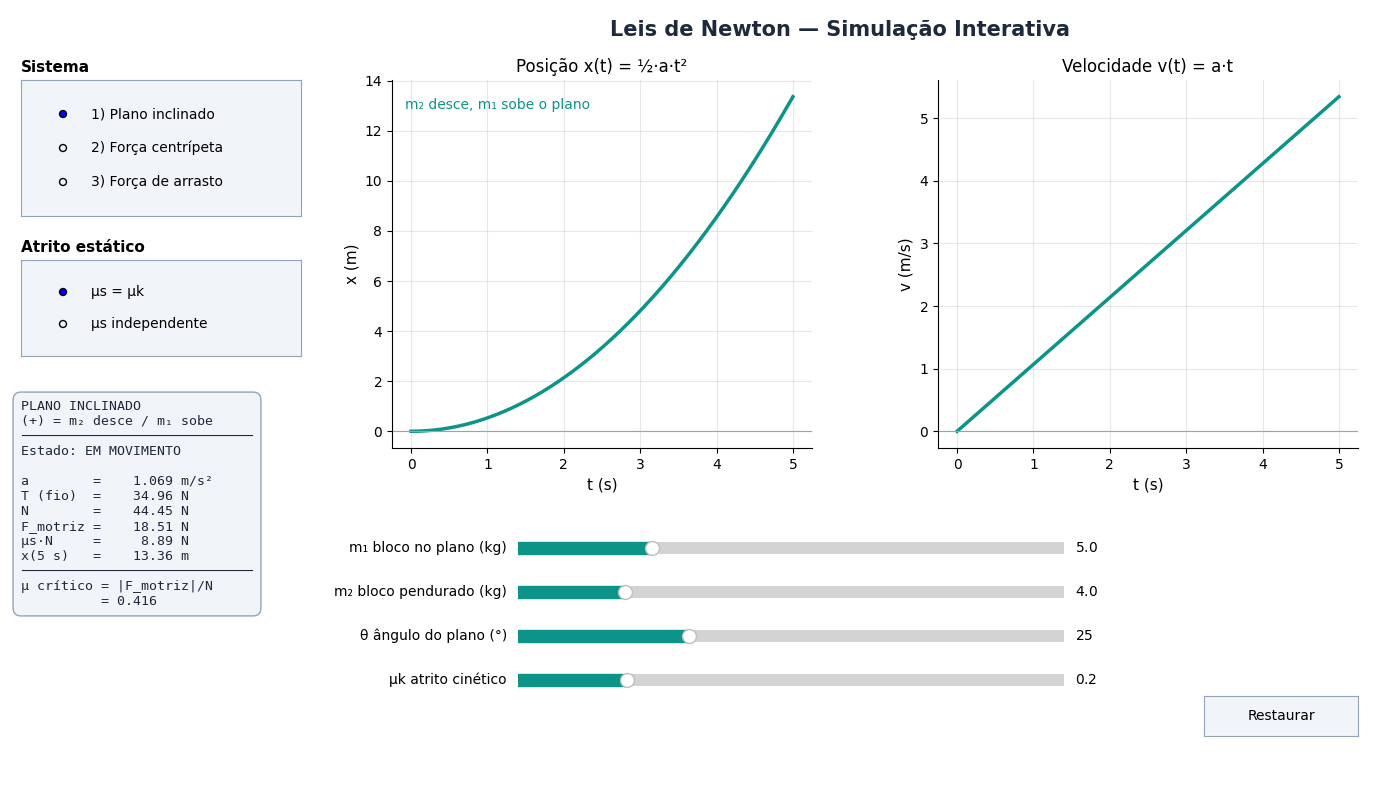

In [15]:
interface = criar_interface()  # guardar em variável mantém os widgets funcionando
plt.show()